# Лабораторная работа: Analiza și explorarea tiparelor — анализ и исследование закономерностей

## Цель
Найти в данных о недвижимости **частые сочетания характеристик** и **правила ассоциаций** («если объект такой-то, то он часто ещё и такой-то»), отделить содержательные правила от очевидных и случайных.

## Задачи
1. Изучить и подготовить данные.
2. Преобразовать числовые признаки в категории и представить каждый объект как *транзакцию* (набор элементов).
3. Найти частые наборы алгоритмами **Apriori** и **FP-Growth** и сравнить их.
4. Построить правила ассоциаций, оценить их по support, confidence, lift и отфильтровать.
5. Проверить, что правила сильнее случайного совпадения и устойчивы к выбору категорий и порогов.
6. Визуализировать результаты и интерпретировать их, не приписывая ассоциациям причинность.

**Файл данных:** `real_estate_regression_dataset.csv`. Исходный файл не изменяется.

## Теоретические основы

**Pattern mining (поиск закономерностей)** — поиск повторяющихся структур в данных без заранее заданной целевой переменной.

**Транзакция и элемент (item).** Классический пример — корзина покупок: транзакция — это набор товаров (хлеб, молоко). Здесь «корзина» — один объект недвижимости, а «товары» — его характеристики: `Area=Large`, `PropertyType=House`, `Price=High`.

**Частый набор элементов (frequent itemset)** — набор, который встречается не реже заданной доли транзакций (`min_support`).

**Правило ассоциации `A → C`** («если A, то C»), где A — *антецедент* (условие), C — *консеквент* (следствие). Три главных метрики:
- **support (поддержка)** = доля объектов, у которых есть и A, и C. Показывает, насколько часто встречается сочетание.
- **confidence (достоверность)** = доля объектов с C среди объектов с A: `support(A и C) / support(A)`. Показывает, насколько «надёжно» выполняется правило.
- **lift (подъём)** = `confidence / support(C)`. Показывает силу связи относительно случайного совпадения: **lift = 1** — A и C независимы; **lift > 1** — встречаются вместе чаще, чем случайно; **lift < 1** — реже.

*Важно:* ассоциация — это статистическое совпадение, а не причинность. Правило «большая площадь → высокая цена» не доказывает, что площадь *вызывает* цену, и не является моделью предсказания цены.

**Apriori** — перебирает наборы по возрастанию размера: сначала частые одиночные элементы, затем пары из них и т. д.; опирается на правило «набор не может быть частым, если частым не является его подмножество», и отсекает лишнее.
**FP-Growth** — сжимает все транзакции в компактное префиксное дерево (FP-tree) и извлекает частые наборы из него, не генерируя большое число кандидатов; на больших данных и при низкой поддержке обычно быстрее.

## Импорт библиотек и загрузка данных
`mlxtend` — библиотека с реализацией Apriori, FP-Growth и правил ассоциаций (в scikit-learn их нет). `networkx` нужен только для графа связей.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
from itertools import combinations
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
RANDOM_STATE = 42

In [2]:
# Данные лежат в папке data/ рядом с папкой notebooks/
DATA_PATH = Path("../data/real_estate_regression_dataset.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Файл данных не найден. Проверьте, что он лежит в папке data/.")
print("Файл найден:", DATA_PATH)

# Папка для результатов
OUT_DIR = Path("../outputs/pattern_mining")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Папка результатов:", OUT_DIR)

df_raw = pd.read_csv(DATA_PATH)       # исходные данные, дальше не изменяются
print("Строк:", df_raw.shape[0], "| Столбцов:", df_raw.shape[1])
df_raw.head()

Файл найден: ../data/real_estate_regression_dataset.csv
Папка результатов: ../outputs/pattern_mining
Строк: 2840 | Столбцов: 28


,Id,Neighborhood,PropertyType,OverallQual,Condition,RenovationQuality,GrLivArea,LotArea,TotalBsmtSF,Rooms,Bedrooms,Bathrooms,Floor,TotalFloors,YearBuilt,YearRenovated,PropertyAge,GarageType,GarageCars,GarageArea,HeatingType,EnergyEfficiency,DistanceToCenter,HasPool,HasBalcony,CrimeRate,SchoolRating,SalePrice
0,994,GreenPark,Townhouse,9,Average,High,121,154.0,104.0,5,4,2,1,2,2016,2024.0,8,Detached,1,22.0,Electric,98.0,4.8,0,0,4.8,9.1,641900
1,279,Eastgate,House,9,Fair,Medium,90,1227.0,50.0,4,3,3,1,2,1982,2018.0,42,Attached,1,17.0,Gas,97.0,7.7,0,0,3.5,5.4,283500
2,820,OldTown,Apartment,4,Good,Low,104,0.0,0.0,3,2,1,1,5,1992,2024.0,32,NoGarage,0,0.0,Gas,97.0,2.5,0,0,4.6,5.9,365300
3,2700,Eastgate,Apartment,5,Good,Low,80,0.0,0.0,4,1,2,6,10,2012,2024.0,12,Underground,1,30.0,District,100.0,8.4,0,1,5.2,9.5,341200
4,1205,Downtown,House,9,Excellent,Medium,156,583.0,135.0,7,5,3,1,1,2018,2024.0,6,Detached,2,49.0,Electric,100.0,0.3,1,0,7.0,6.7,1238000


## EDA
Изучаем структуру: типы, пропуски, дубликаты, распределения и редкие категории.

In [3]:
info = pd.DataFrame({"тип": df_raw.dtypes, "пропусков": df_raw.isna().sum(),
                     "доля пропусков, %": (df_raw.isna().mean() * 100).round(1),
                     "уникальных": df_raw.nunique()})
print(info.to_string())
print("\nПолных дубликатов:", df_raw.duplicated().sum())

                       тип  пропусков  доля пропусков, %  уникальных
Id                   int64          0                0.0        2800
Neighborhood        object          0                0.0          13
PropertyType        object          0                0.0           6
OverallQual          int64          0                0.0          10
Condition           object        145                5.1           6
RenovationQuality   object        245                8.6           3
GrLivArea            int64          0                0.0         281
LotArea            float64        145                5.1         832
TotalBsmtSF        float64        249                8.8         205
Rooms                int64          0                0.0          10
Bedrooms             int64          0                0.0          11
Bathrooms            int64          0                0.0           7
Floor                int64          0                0.0          19
TotalFloors          int64        

In [4]:
# Статистики числовых признаков (без Id)
num_all = df_raw.select_dtypes(include="number").columns.drop("Id")
df_raw[num_all].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
OverallQual,2840.0,6.1,1.6,1.0,5.0,6.0,7.0,10.0
GrLivArea,2840.0,128.9,59.0,29.0,84.0,120.0,159.0,538.0
LotArea,2695.0,338.0,556.1,0.0,0.0,221.0,463.5,11197.0
TotalBsmtSF,2591.0,55.4,56.5,0.0,0.0,53.0,92.0,449.0
Rooms,2840.0,5.4,1.8,2.0,4.0,5.0,6.0,11.0
Bedrooms,2840.0,3.4,1.6,1.0,2.0,3.0,4.0,12.0
Bathrooms,2840.0,2.2,1.0,1.0,1.0,2.0,3.0,7.0
Floor,2840.0,2.6,3.3,1.0,1.0,1.0,2.0,19.0
TotalFloors,2840.0,4.8,5.1,1.0,2.0,2.0,7.0,19.0
YearBuilt,2840.0,1988.8,21.0,1890.0,1975.0,1989.0,2004.0,2024.0


In [5]:
# Редкие категории (доля < 1%): такие элементы всё равно не пройдут порог поддержки
cat_all = df_raw.select_dtypes(exclude="number").columns
for c in cat_all:
    share = df_raw[c].value_counts(normalize=True)
    rare = share[share < 0.01]
    print(f"{c}: категорий {len(share)}, редких (<1%): {rare.round(4).to_dict()}")

Neighborhood: категорий 13, редких (<1%): {'Harbor Point': 0.0011, 'Castle Hill': 0.0011}
PropertyType: категорий 6, редких (<1%): {'Penthouse': 0.0014}
Condition: категорий 6, редких (<1%): {'Needs Demolition': 0.0011}
RenovationQuality: категорий 3, редких (<1%): {}
GarageType: категорий 6, редких (<1%): {}
HeatingType: категорий 7, редких (<1%): {'Geothermal': 0.0011}


## Подготовка и категоризация признаков

**Дубликаты** удаляем: повторные строки удваивают «вес» одних и тех же объектов и искусственно повышают поддержку.

**Пропуски** — в отличие от предыдущих работ, здесь **не заполняем**. В поиске ассоциаций транзакция — это просто набор имеющихся характеристик: если значения нет, элемент в транзакцию не попадает. Это честнее, чем подставлять «самое частое значение» (например, приписать всем без данных гараж `Attached`), потому что такая подстановка создала бы искусственную ассоциацию.

**Выбросы** не удаляем: при разбиении на интервалы они просто попадают в крайние категории и не искажают границы (используем квантили).

**Почему числа нельзя подать в алгоритм как есть.** Apriori и FP-Growth считают, как часто элементы *повторяются*. У непрерывного признака (площадь 143.7, 143.8, ...) почти каждое значение уникально, поэтому поддержка каждого «элемента» ≈ 1/2800 и частых наборов не будет. Нужно сгруппировать значения в небольшое число осмысленных интервалов. Слишком мелкое дробление, наоборот, создаёт много редких бессмысленных элементов, поэтому берём 2–3 интервала.

**Выбор признаков.** Используем характеристики объекта и окружения. Исключаем `Id` (номер), а также признаки-дубликаты и зависимые функции: `YearBuilt` (копия `PropertyAge`), `Rooms` и `GarageCars`/`GarageArea` (почти повторяют спальни и тип гаража), `Floor`/`TotalFloors` (осмысленны только для квартир), `YearRenovated`, `TotalBsmtSF` (сильно связан с площадью). Цена (`SalePrice`) **включена** как элемент `Price=...` — чтобы искать, с какими сочетаниями связаны ценовые диапазоны; это исследовательская ассоциация, а не модель предсказания.

In [6]:
# Удаляем полные дубликаты (пропуски пока оставляем)
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Удалено дубликатов: {len(df_raw) - len(df)}. Осталось объектов: {len(df)}")

Удалено дубликатов: 40. Осталось объектов: 2800


In [7]:
# Категоризация числовых признаков.
# Метод: квантили (равные по размеру группы), если нет очевидных «естественных» границ; для OverallQual, спален и ванных — границы по смыслу.
def tercile(s, labels):
    # три группы равного размера по квантилям; rank(method="first") устраняет проблему повторяющихся границ
    r = s.rank(method="first")
    return pd.qcut(r, 3, labels=labels).where(s.notna())

T = pd.DataFrame(index=df.index)
T["Area"] = tercile(df["GrLivArea"], ["Small", "Medium", "Large"])                  # жилая площадь
lot_median = df.loc[df["LotArea"] > 0, "LotArea"].median()
T["Lot"] = np.select([df["LotArea"] == 0, df["LotArea"] <= lot_median], ["NoLot", "SmallLot"], "LargeLot")
T["Lot"] = T["Lot"].where(df["LotArea"].notna())                                      # участок: нет / малый / большой
T["Bedrooms"] = pd.cut(df["Bedrooms"], [0, 2, 3, 99], labels=["1-2", "3", "4+"])     # спальни
T["Bathrooms"] = pd.cut(df["Bathrooms"], [0, 1, 2, 99], labels=["1", "2", "3+"])     # ванные
T["Quality"] = pd.cut(df["OverallQual"], [0, 5, 7, 10], labels=["Low", "Medium", "High"])  # качество 1-5 / 6-7 / 8-10
T["Age"] = tercile(df["PropertyAge"], ["New", "Middle", "Old"])                      # возраст
T["Distance"] = tercile(df["DistanceToCenter"], ["Central", "Middle", "Far"])        # расстояние до центра
T["Energy"] = tercile(df["EnergyEfficiency"], ["Low", "Medium", "High"])             # энергоэффективность
T["Crime"] = tercile(df["CrimeRate"], ["Low", "Medium", "High"])                     # преступность района
T["School"] = tercile(df["SchoolRating"], ["Low", "Medium", "High"])                 # рейтинг школ
T["Price"] = tercile(df["SalePrice"], ["Low", "Mid", "High"])                        # цена: низкая / средняя / высокая

# Исходные категориальные признаки; категории реже 1% объединяем в «Other»
for c in ["PropertyType", "Neighborhood", "Condition", "HeatingType", "GarageType", "RenovationQuality"]:
    share = df[c].value_counts(normalize=True)
    rare = share[share < 0.01].index
    T[c] = df[c].where(~df[c].isin(rare), "Other")

# Бинарные признаки: берём только наличие (отсутствие бассейна — не информативный элемент)
T["Pool"] = np.where(df["HasPool"] == 1, "Pool", None)
T["Balcony"] = np.where(df["HasBalcony"] == 1, "Balcony", None)

# Границы интервалов (для отчёта)
edges = {
    "Area (GrLivArea, м²)": df.groupby(T["Area"], observed=True)["GrLivArea"].agg(["min", "max"]),
    "Distance (км)": df.groupby(T["Distance"], observed=True)["DistanceToCenter"].agg(["min", "max"]),
    "Price": df.groupby(T["Price"], observed=True)["SalePrice"].agg(["min", "max"]),
    "Age (лет)": df.groupby(T["Age"], observed=True)["PropertyAge"].agg(["min", "max"]),
}
for k, v in edges.items():
    print(k); print(v.round(1).to_string()); print()

Area (GrLivArea, м²)
        min  max
Area            
Small    29   98
Medium   98  143
Large   143  538

Distance (км)
          min   max
Distance           
Central   0.3   3.6
Middle    3.6   8.2
Far       8.2  14.7

Price
          min      max
Price                 
Low     82500   364800
Mid    365300   523200
High   523200  2951700

Age (лет)
        min  max
Age             
New       0   26
Middle   26   44
Old      44  134



## Создание транзакций
Каждая строка таблицы превращается в набор элементов вида `Признак=Значение`. Затем строим булеву матрицу «транзакция × элемент» (True — элемент присутствует): именно такой формат требуют алгоритмы `mlxtend`.

In [8]:
# Транзакции: список элементов для каждого объекта (пропущенные значения элемента не дают)
transactions = [[f"{c}={v}" for c, v in row.items() if pd.notna(v) and v is not None] for _, row in T.iterrows()]

# Булева матрица «транзакция × элемент»
items = sorted({i for t in transactions for i in t})
B = pd.DataFrame(False, index=range(len(transactions)), columns=items)
for k, t in enumerate(transactions):
    B.loc[k, t] = True

print("Транзакций:", B.shape[0], "| различных элементов:", B.shape[1])
print("Среднее число элементов в транзакции:", round(B.sum(axis=1).mean(), 1))
print("\nПримеры транзакций:")
for k in (0, 1, 2):
    print(f"#{k}:", transactions[k])

Транзакций: 2800 | различных элементов: 75
Среднее число элементов в транзакции: 16.9

Примеры транзакций:
#0: ['Area=Medium', 'Lot=SmallLot', 'Bedrooms=4+', 'Bathrooms=2', 'Quality=High', 'Age=New', 'Distance=Middle', 'Energy=High', 'Crime=Low', 'School=High', 'Price=High', 'PropertyType=Townhouse', 'Neighborhood=GreenPark', 'Condition=Average', 'HeatingType=Electric', 'GarageType=Detached', 'RenovationQuality=High']
#1: ['Area=Small', 'Lot=LargeLot', 'Bedrooms=3', 'Bathrooms=3+', 'Quality=High', 'Age=Middle', 'Distance=Middle', 'Energy=High', 'Crime=Low', 'School=Low', 'Price=Low', 'PropertyType=House', 'Neighborhood=Eastgate', 'Condition=Fair', 'HeatingType=Gas', 'GarageType=Attached', 'RenovationQuality=Medium']
#2: ['Area=Medium', 'Lot=NoLot', 'Bedrooms=1-2', 'Bathrooms=1', 'Quality=Low', 'Age=Middle', 'Distance=Central', 'Energy=High', 'Crime=Low', 'School=Low', 'Price=Mid', 'PropertyType=Apartment', 'Neighborhood=OldTown', 'Condition=Good', 'HeatingType=Gas', 'GarageType=NoGarag

**Как устроены транзакции.** Каждая транзакция — одна запись о недвижимости, записанная как набор элементов, например: `Area=Small`, `PropertyType=Apartment`, `Lot=NoLot`, `Price=Low` и т. д. Порядок элементов не важен; у объекта с пропусками в данных (например, неизвестна энергоэффективность) просто нет соответствующего элемента.

In [9]:
# Поддержка отдельных элементов: нет ли «слишком распространённых» элементов, которые порождают правила сами по себе?
item_support = B.mean().sort_values(ascending=False)
print("Самые частые элементы:"); print(item_support.head(8).round(3).to_string())
print("\nСамые редкие элементы:"); print(item_support.tail(5).round(3).to_string())
print("\nЭлементов с поддержкой > 0.6:", int((item_support > 0.6).sum()))

# Сохраняем транзакции
pd.Series([", ".join(t) for t in transactions], name="transaction").to_csv(OUT_DIR / "transactions.csv", index=False)

Самые частые элементы:
Quality=Medium              0.468
RenovationQuality=Medium    0.461
Bedrooms=4+                 0.429
Balcony=Balcony             0.381
Condition=Average           0.376
PropertyType=House          0.372
Bathrooms=2                 0.367
Bathrooms=3+                0.360

Самые редкие элементы:
HeatingType=Solid fuel    0.030
Neighborhood=Other        0.002
PropertyType=Other        0.001
Condition=Other           0.001
HeatingType=Other         0.001

Элементов с поддержкой > 0.6: 0


## Apriori
Сначала исследуем, как число частых наборов зависит от `min_support`: чем ниже порог, тем больше наборов (и шума). Ограничиваем длину набора `max_len=4`: более длинные наборы трудно читать и они быстро становятся редкими.

In [10]:
MAX_LEN = 4
rows = []
for ms in (0.03, 0.05, 0.10, 0.15, 0.20):
    fi = apriori(B, min_support=ms, use_colnames=True, max_len=MAX_LEN)
    sizes = fi["itemsets"].apply(len).value_counts().sort_index()
    rows.append({"min_support": ms, "частых наборов": len(fi), **{f"размер {k}": int(v) for k, v in sizes.items()}})
pd.DataFrame(rows)

,min_support,частых наборов,размер 1,размер 2,размер 3,размер 4
0,0.03,12577,71,1423,6961,4122.0
1,0.05,3804,66,1036,1823,879.0
2,0.10,734,56,499,127,52.0
3,0.15,175,47,90,30,8.0
4,0.20,76,44,25,7,NaN


**Как читать:** при `min_support=0.03` наборов очень много (многие — случайные комбинации редких элементов), при `0.20` остаётся лишь самое массовое. Для дальнейшей работы берём **`min_support = 0.05`**: набор должен встречаться не менее чем у 5% объектов (≈140 объектов), этого достаточно, чтобы закономерность не была единичной.

In [11]:
MIN_SUPPORT = 0.05
fi_ap = apriori(B, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
fi_ap["size"] = fi_ap["itemsets"].apply(len)
fi_ap["itemsets_str"] = fi_ap["itemsets"].apply(lambda s: " + ".join(sorted(s)))
print("Частых наборов (min_support = 0.05):", len(fi_ap))

# Самые частые наборы из двух и более элементов
fi_ap[fi_ap["size"] >= 2].sort_values("support", ascending=False)[["itemsets_str", "support", "size"]].head(10).round(3)

Частых наборов (min_support = 0.05): 3804


,itemsets_str,support,size
422,Bathrooms=3+ + Bedrooms=4+,0.304,2
979,Lot=NoLot + PropertyType=Apartment,0.304,2
201,Area=Large + Bedrooms=4+,0.301,2
300,Area=Small + PropertyType=Apartment,0.268,2
296,Area=Small + Lot=NoLot,0.252,2
1804,Area=Small + Lot=NoLot + PropertyType=Apartment,0.251,3
278,Area=Small + Bedrooms=1-2,0.250,2
967,Lot=LargeLot + PropertyType=House,0.249,2
547,Bedrooms=4+ + PropertyType=House,0.246,2
340,Balcony=Balcony + PropertyType=Apartment,0.245,2


## Генерация и фильтрация правил
Из частых наборов строим правила `A → C`. Их получается очень много, и большинство бесполезны, поэтому фильтруем в несколько шагов:

1. **Простая форма:** одно следствие (`C` — один элемент), условие из 1–3 элементов.
2. **Порог качества:** `support ≥ 0.05`, `confidence ≥ 0.6`, `lift ≥ 1.2` (связь заметно сильнее случайной).
3. **Без избыточных и случайных правил:** правило отбрасываем, если добавление элементов в условие не повышает достоверность по сравнению с более простым правилом (*improvement*) хотя бы на 0.02 **и** этот прирост не укладывается в обычный случайный разброс. Для второго условия считаем z-статистику: `z = (conf − conf_простого правила) / √(conf_простого·(1 − conf_простого) / n)`, где n — число объектов, подходящих под условие; оставляем правила с `z ≥ 2`. Например, если `Area=Small, Bedrooms=1-2 → Lot=NoLot` уже достоверно, то добавление к условию `HeatingType=Gas`, поднимающее достоверность на 4% на ~240 объектах, — это шум, а не закономерность. Это эвристика, а не строгая поправка на множественные сравнения: правил проверяется очень много, поэтому часть случайных всё равно может пройти.
4. **Пометка очевидных правил:** элементы сгруппированы по темам (размер, расположение, устройство, качество, цена). Если следствие из той же темы, что и условие (например, `Area=Large → Bedrooms=4+`), правило *ожидаемо*; самые содержательные — правила «между темами».

In [12]:
# Темы признаков (для разметки очевидных правил)
THEME = {"Area": "размер", "Bedrooms": "размер", "Bathrooms": "размер",
         "Neighborhood": "расположение", "Distance": "расположение", "Crime": "расположение", "School": "расположение",
         "PropertyType": "устройство", "Lot": "устройство", "GarageType": "устройство", "Balcony": "устройство", "Pool": "устройство",
         "Quality": "качество", "Condition": "качество", "RenovationQuality": "качество", "Age": "качество",
         "Energy": "качество", "HeatingType": "качество",
         "Price": "цена"}
feat = lambda item: item.split("=")[0]

N_TRANS = len(B)

def make_rules(fi, min_conf=0.6, min_lift=1.2, min_improvement=0.02, min_z=2.0, max_ante=3):
    # Строим правила из частых наборов, фильтруем и считаем improvement
    sup = {frozenset(s): v for s, v in zip(fi["itemsets"], fi["support"])}
    r = association_rules(fi, metric="lift", min_threshold=min_lift)
    r = r[(r["consequents"].apply(len) == 1) & (r["antecedents"].apply(len) <= max_ante) & (r["confidence"] >= min_conf)].copy()

    def improvement(row):
        # достоверность простейшего «родительского» правила (подмножество условия) и z-статистика прироста
        A, Cc = row["antecedents"], row["consequents"]
        best = 0.0
        for k in range(1, len(A)):
            for sub in combinations(A, k):
                sub = frozenset(sub)
                best = max(best, sup[sub | Cc] / sup[sub])
        n = row["antecedent support"] * N_TRANS
        z = np.inf if best == 0 else (row["confidence"] - best) / np.sqrt(max(best * (1 - best), 1e-9) / n)
        return pd.Series({"improvement": row["confidence"] - best, "z": z})
    r[["improvement", "z"]] = r.apply(improvement, axis=1)
    r = r[(r["improvement"] >= min_improvement) & (r["z"] >= min_z)].copy()

    r["theme_ante"] = r["antecedents"].apply(lambda s: {THEME[feat(i)] for i in s})
    r["theme_cons"] = r["consequents"].apply(lambda s: THEME[feat(next(iter(s)))])
    r["expected"] = [tc in ta for ta, tc in zip(r["theme_ante"], r["theme_cons"])]
    r["rule"] = r["antecedents"].apply(lambda s: ", ".join(sorted(s))) + "  →  " + r["consequents"].apply(lambda s: next(iter(s)))
    return r.sort_values(["lift", "support"], ascending=False).reset_index(drop=True)

rules_all = association_rules(fi_ap, metric="lift", min_threshold=1.0)
print("Всего правил (lift > 1, без фильтров):", len(rules_all))
rules = make_rules(fi_ap)
print("После фильтрации (1 следствие, conf ≥ 0.6, lift ≥ 1.2, improvement ≥ 0.02, z ≥ 2):", len(rules))
print("  из них «ожидаемых» (следствие из той же темы, что и условие):", int(rules["expected"].sum()))
print("  из них «между темами»:", int((~rules["expected"]).sum()))

Всего правил (lift > 1, без фильтров): 21602
После фильтрации (1 следствие, conf ≥ 0.6, lift ≥ 1.2, improvement ≥ 0.02, z ≥ 2): 324
  из них «ожидаемых» (следствие из той же темы, что и условие): 149
  из них «между темами»: 175


In [13]:
# Как выглядят метрики одного правила — разбор «по шагам»
r0 = rules[~rules["expected"]].iloc[0]
A, Cc = r0["antecedents"], next(iter(r0["consequents"]))
mA = B[list(A)].all(axis=1); mC = B[Cc]
print("Правило:", r0["rule"])
print(f"support    = P(A и C)    = {(mA & mC).mean():.3f}  ({(mA & mC).sum()} объектов из {len(B)})")
print(f"confidence = P(C | A)    = {(mA & mC).sum()} / {mA.sum()} = {(mA & mC).sum() / mA.sum():.3f}")
print(f"support(C) = P(C)        = {mC.mean():.3f}")
print(f"lift       = conf / P(C) = {(mA & mC).sum() / mA.sum() / mC.mean():.2f}")
print()
print(f"Читаем: среди объектов с условием «{', '.join(sorted(A))}» {(mA & mC).sum() / mA.sum() * 100:.0f}% имеют {Cc}; "
      f"в целом {Cc} встречается у {mC.mean() * 100:.0f}% объектов, то есть связь в {(mA & mC).sum() / mA.sum() / mC.mean():.1f} раза сильнее случайной.")

Правило: Area=Large, Bathrooms=3+, Distance=Central  →  Price=High
support    = P(A и C)    = 0.077  (215 объектов из 2800)
confidence = P(C | A)    = 215 / 235 = 0.915
support(C) = P(C)        = 0.334
lift       = conf / P(C) = 2.74

Читаем: среди объектов с условием «Area=Large, Bathrooms=3+, Distance=Central» 91% имеют Price=High; в целом Price=High встречается у 33% объектов, то есть связь в 2.7 раза сильнее случайной.


In [14]:
# Содержательные правила, где следствие — ценовой диапазон (исследовательская ассоциация, не модель предсказания цены)
price_rules = rules[rules["consequents"].apply(lambda s: next(iter(s)).startswith("Price="))]
show = ["rule", "support", "confidence", "lift", "improvement"]
print("Топ правил со следствием «Price=High»:")
display(price_rules[price_rules["consequents"].apply(lambda s: "Price=High" in s)].head(8)[show].round(3))
print("Топ правил со следствием «Price=Low»:")
display(price_rules[price_rules["consequents"].apply(lambda s: "Price=Low" in s)].head(8)[show].round(3))

Топ правил со следствием «Price=High»:


,rule,support,confidence,lift,improvement
41,"Area=Large, Bathrooms=3+, Distance=Central → Price=High",0.077,0.915,2.743,0.050
68,"Area=Large, Distance=Central → Price=High",0.099,0.865,2.594,0.217
73,"Bedrooms=4+, Distance=Central, Lot=LargeLot → Price=High",0.072,0.845,2.534,0.071
74,"Bathrooms=3+, Bedrooms=4+, Distance=Central → Price=High",0.088,0.845,2.533,0.071
75,"Bathrooms=3+, Distance=Central, Lot=LargeLot → Price=High",0.058,0.845,2.532,0.095
79,"Area=Large, Bathrooms=3+, Crime=Low → Price=High",0.056,0.839,2.514,0.076
84,"Area=Large, Crime=Low, Lot=LargeLot → Price=High",0.051,0.830,2.489,0.068
98,"Area=Large, Quality=High → Price=High",0.052,0.815,2.442,0.167


Топ правил со следствием «Price=Low»:


,rule,support,confidence,lift,improvement
42,"Area=Small, Distance=Far → Price=Low",0.101,0.910,2.731,0.304
45,"Bedrooms=1-2, Distance=Far → Price=Low",0.099,0.903,2.709,0.304
60,"Distance=Far, PropertyType=Apartment → Price=Low",0.096,0.873,2.621,0.286
63,"Distance=Far, Lot=NoLot → Price=Low",0.091,0.870,2.611,0.283
93,"Bathrooms=1, Distance=Far → Price=Low",0.079,0.824,2.473,0.263
114,"Area=Small, Quality=Low → Price=Low",0.090,0.783,2.349,0.177
115,Neighborhood=Industrial → Price=Low,0.057,0.780,2.342,0.780
124,"Age=Old, Bedrooms=1-2, PropertyType=Apartment → Price=Low",0.055,0.770,2.311,0.070


In [15]:
# Правила между темами, где следствие НЕ цена: какие характеристики сочетаются неочевидным образом
other = rules[(~rules["expected"]) & (~rules["consequents"].apply(lambda s: next(iter(s)).startswith("Price=")))]
print("Правил между темами (следствие не цена):", len(other))
display(other.head(10)[show + ["theme_cons"]].round(3))

Правил между темами (следствие не цена): 76


,rule,support,confidence,lift,improvement,theme_cons
52,"Age=Old, Lot=LargeLot, Price=High → Area=Large",0.052,0.890,2.667,0.066,размер
55,"Lot=NoLot, Price=Low → Area=Small",0.157,0.880,2.641,0.053,размер
58,"Price=Low, PropertyType=Apartment → Area=Small",0.167,0.878,2.634,0.050,размер
64,"Area=Small, Bedrooms=1-2 → Lot=NoLot",0.199,0.794,2.610,0.039,устройство
66,"Area=Small, Bedrooms=1-2 → PropertyType=Apartment",0.210,0.840,2.599,0.037,устройство
85,GarageType=Underground → Area=Small,0.119,0.828,2.486,0.828,размер
87,Area=Small → PropertyType=Apartment,0.268,0.803,2.484,0.803,устройство
88,PropertyType=Apartment → Area=Small,0.268,0.828,2.484,0.828,размер
89,Area=Small → Lot=NoLot,0.252,0.756,2.483,0.756,устройство
90,Lot=NoLot → Area=Small,0.252,0.827,2.483,0.827,размер


In [16]:
# Ожидаемые (почти очевидные) правила: для контраста
exp = rules[rules["expected"]]
print("Ожидаемые правила с высокой достоверностью (confidence ≥ 0.9):", int((exp["confidence"] >= 0.9).sum()))
display(exp.head(6)[show].round(3))

Ожидаемые правила с высокой достоверностью (confidence ≥ 0.9): 47


,rule,support,confidence,lift,improvement
0,PropertyType=Apartment → Lot=NoLot,0.304,0.940,3.090,0.940
1,Lot=NoLot → PropertyType=Apartment,0.304,0.999,3.090,0.999
2,GarageType=Underground → Lot=NoLot,0.135,0.938,3.082,0.938
3,GarageType=Underground → PropertyType=Apartment,0.143,0.995,3.079,0.995
4,"Area=Small, Balcony=Balcony, School=Low → Lot=NoLot",0.065,0.928,3.050,0.047
5,"Area=Small, Balcony=Balcony, GarageType=NoGarage → PropertyType=Apartment",0.082,0.979,3.028,0.039


### Проверка: правила сильнее случайного совпадения?
Если перемешать значения **каждого столбца независимо**, все связи между признаками разрушатся, а частоты отдельных элементов останутся прежними. Если на таких «перемешанных» данных те же алгоритмы с теми же порогами находят мало правил, значит, найденные на реальных данных правила не следствие одних лишь частот элементов.

In [17]:
rng = np.random.default_rng(RANDOM_STATE)
counts = []
for rep in range(5):
    Ts = T.apply(lambda col: pd.Series(rng.permutation(col.values), index=col.index))
    Bs = pd.DataFrame({f"{c}={v}": (Ts[c] == v) for c in Ts.columns for v in Ts[c].dropna().unique()})
    fs = apriori(Bs, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
    try:
        rs = make_rules(fs)
        counts.append(len(rs))
    except Exception:
        counts.append(0)
print("Правил после тех же фильтров на реальных данных:", len(rules))
print("Правил на данных с независимо перемешанными столбцами (5 повторов):", counts)

Правил после тех же фильтров на реальных данных: 324
Правил на данных с независимо перемешанными столбцами (5 повторов): [0, 0, 0, 0, 0]


**Как читать:** на перемешанных данных (где связей нет по построению) правила практически не проходят фильтры, а на реальных — проходят. Следовательно, найденные ассоциации не артефакт частот; они отражают реальные зависимости *в этом датасете* (напомним, он синтетический).

### Проверка: нет ли зависимости от категоризации и порога поддержки
Возьмём одно правило — `Area=Large → Price=High` — и посмотрим, как меняется его lift при разных способах разбиения площади и цены. Затем проверим, как число правил зависит от `min_support`.

In [18]:
# Разные способы категоризации площади и цены; lift правила «большая площадь → высокая цена»
def area_variants(s):
    return {
        "Площадь: терцили (3 группы)": s > s.quantile(2 / 3),
        "Площадь: медиана (верхняя половина)": s > s.median(),
        "Площадь: равные интервалы (верхний из 3)": pd.cut(s, 3, labels=False) == 2,
    }
def price_variants(s):
    return {
        "Цена: верхний терциль": s > s.quantile(2 / 3),
        "Цена: верхняя половина": s > s.median(),
        "Цена: верхний квинтиль (20%)": s > s.quantile(0.8),
    }
res = {}
for an, am in area_variants(df["GrLivArea"]).items():
    for pn, pm in price_variants(df["SalePrice"]).items():
        conf = (am & pm).sum() / am.sum()
        res.setdefault(an, {})[pn] = round(conf / pm.mean(), 2)
print("Lift правила «большая площадь → высокая цена» при разных разбиениях:")
display(pd.DataFrame(res).T)
print("Доля объектов с «большой площадью» при разных разбиениях:",
      {k: round(v.mean(), 3) for k, v in area_variants(df["GrLivArea"]).items()})

Lift правила «большая площадь → высокая цена» при разных разбиениях:


,Цена: верхний терциль,Цена: верхняя половина,Цена: верхний квинтиль (20%)
Площадь: терцили (3 группы),1.95,1.63,2.30
Площадь: медиана (верхняя половина),1.63,1.46,1.78
Площадь: равные интервалы (верхний из 3),3.00,2.00,5.00


Доля объектов с «большой площадью» при разных разбиениях: {'Площадь: терцили (3 группы)': np.float64(0.332), 'Площадь: медиана (верхняя половина)': np.float64(0.495), 'Площадь: равные интервалы (верхний из 3)': np.float64(0.004)}


In [19]:
# Зависимость числа правил от min_support
rows = []
for ms in (0.03, 0.05, 0.08, 0.10, 0.15):
    f = apriori(B, min_support=ms, use_colnames=True, max_len=MAX_LEN)
    r = make_rules(f)
    rows.append({"min_support": ms, "частых наборов": len(f), "правил после фильтров": len(r),
                 "из них между темами": int((~r["expected"]).sum()),
                 "правило Area=Large → Price=High найдено":
                     bool(((r["rule"] == "Area=Large  →  Price=High")).any())})
pd.DataFrame(rows)

,min_support,частых наборов,правил после фильтров,из них между темами,правило Area=Large → Price=High найдено
0,0.03,12577,503,319,True
1,0.05,3804,324,175,True
2,0.08,1245,190,87,True
3,0.10,734,146,62,True
4,0.15,175,91,35,True


**Как читать.** Lift зависит от способа разбиения: он **ограничен сверху величиной `1 / support(C)`** (чем реже следствие, тем выше потолок), поэтому нельзя сравнивать lift правил с разной частотой следствия «в лоб». Связь «большая площадь — высокая цена» сохраняется при всех разбиениях (lift > 1), но конкретные числа различаются в несколько раз. Особенно показателен вариант с равными интервалами: из-за выбросов в «большую» категорию попадает меньше 1% объектов (см. строку с долями выше), и его огромный lift опирается на единицы объектов — это пример *неудачной* категоризации, которая даёт красивое, но ненадёжное число. Число правил заметно зависит от `min_support`; это нормально и именно поэтому порог нужно выбирать осознанно и сообщать.

## FP-Growth и сравнение с Apriori
Применяем FP-Growth к тем же транзакциям с теми же параметрами (`min_support`, `max_len`). Проверяем, что набор частых наборов **одинаков**, и сравниваем время. Время измеряем несколько раз и берём минимум, чтобы уменьшить влияние случайных задержек.

In [20]:
fi_fp = fpgrowth(B, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
set_ap = {frozenset(s) for s in fi_ap["itemsets"]}
set_fp = {frozenset(s) for s in fi_fp["itemsets"]}
print("Apriori:", len(set_ap), "наборов | FP-Growth:", len(set_fp), "наборов")
print("Наборы совпадают полностью:", set_ap == set_fp)

# Поддержки совпадают?
m = fi_ap.set_index(fi_ap["itemsets"].apply(frozenset))["support"]
n = fi_fp.set_index(fi_fp["itemsets"].apply(frozenset))["support"]
print("Максимальное расхождение поддержек:", float((m - n.reindex(m.index)).abs().max()))

Apriori: 3804 наборов | FP-Growth: 3804 наборов
Наборы совпадают полностью: True
Максимальное расхождение поддержек: 0.0


In [21]:
# Время выполнения при разных порогах поддержки (минимум из 3 запусков)
def best_time(func, reps=3):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); func(); ts.append(time.perf_counter() - t0)
    return min(ts)

rows = []
for ms in (0.03, 0.05, 0.10, 0.20):
    ta = best_time(lambda: apriori(B, min_support=ms, use_colnames=True, max_len=MAX_LEN))
    tf = best_time(lambda: fpgrowth(B, min_support=ms, use_colnames=True, max_len=MAX_LEN))
    rows.append({"min_support": ms, "Apriori, сек": round(ta, 3), "FP-Growth, сек": round(tf, 3)})
timing = pd.DataFrame(rows)
timing

,min_support,"Apriori, сек","FP-Growth, сек"
0,0.03,1.044,27.431
1,0.05,0.310,8.536
2,0.10,0.057,1.637
3,0.20,0.006,0.168


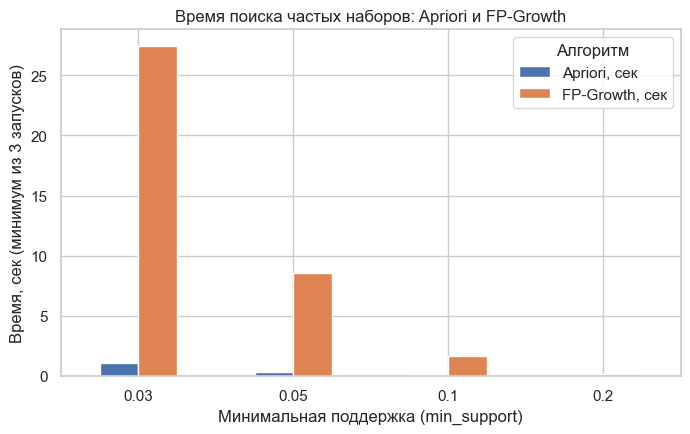

In [22]:
timing.set_index("min_support").plot(kind="bar", figsize=(8, 4.5), rot=0)
plt.title("Время поиска частых наборов: Apriori и FP-Growth")
plt.xlabel("Минимальная поддержка (min_support)")
plt.ylabel("Время, сек (минимум из 3 запусков)")
plt.legend(title="Алгоритм")
plt.show()

**Как читать результат.** Оба алгоритма находят *одни и те же* наборы — различаются только способом поиска. Теоретически FP-Growth выигрывает на больших данных и при низкой поддержке, так как не генерирует кандидатов. Здесь данные небольшие (2800 транзакций) и длина наборов ограничена `max_len=4`, а в `mlxtend` Apriori реализован на векторных операциях, поэтому разница во времени определяется скорее реализацией библиотеки, чем теорией. Вывод о «преимуществе» метода по этому замеру переносить на другие данные нельзя; на практике FP-Growth предпочтительнее для больших транзакционных данных.

## Визуализация

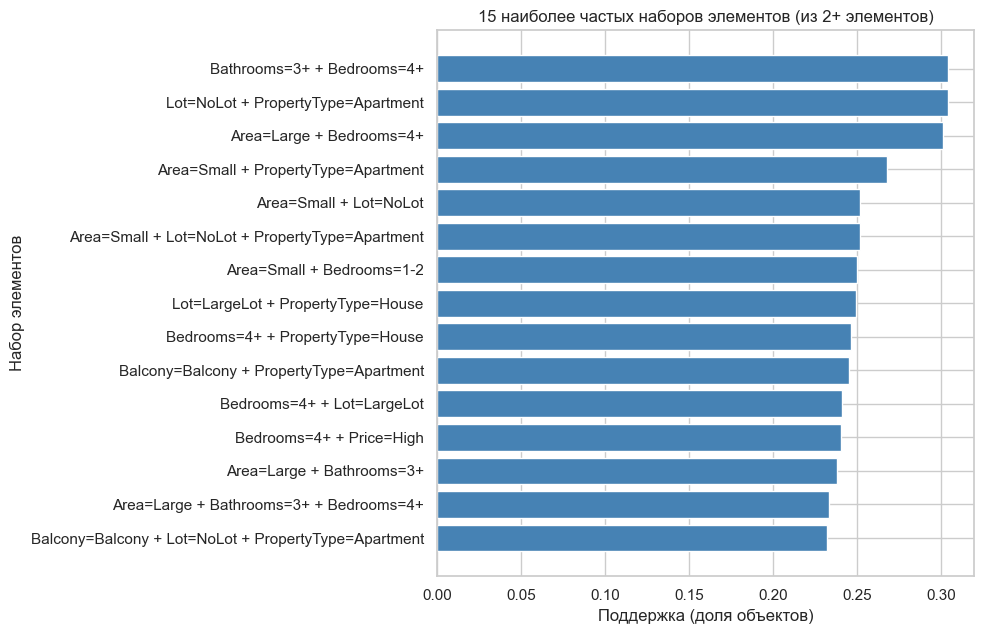

In [23]:
# 1. Самые частые наборы из 2+ элементов
top_fi = fi_ap[fi_ap["size"] >= 2].sort_values("support", ascending=False).head(15).iloc[::-1]
plt.figure(figsize=(10, 6.5))
plt.barh(top_fi["itemsets_str"], top_fi["support"], color="steelblue")
plt.title("15 наиболее частых наборов элементов (из 2+ элементов)")
plt.xlabel("Поддержка (доля объектов)")
plt.ylabel("Набор элементов")
plt.tight_layout()
plt.show()

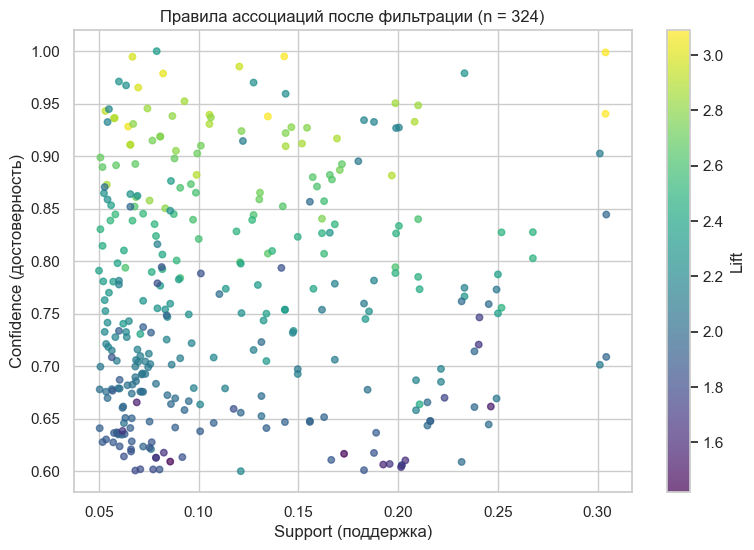

In [24]:
# 2. Правила: support против confidence, цвет — lift
plt.figure(figsize=(9, 6))
sc = plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", s=22, alpha=0.7)
plt.colorbar(sc, label="Lift")
plt.title(f"Правила ассоциаций после фильтрации (n = {len(rules)})")
plt.xlabel("Support (поддержка)")
plt.ylabel("Confidence (достоверность)")
plt.show()

In [25]:
# 3. Таблица наиболее интересных правил: между темами, высокий lift, поддержка не менее 0.07
interesting = rules[(~rules["expected"]) & (rules["support"] >= 0.07)].sort_values("lift", ascending=False).head(12)
table = interesting[["rule", "support", "confidence", "lift"]].round(3)
table.to_csv(OUT_DIR / "interesting_rules.csv", index=False)
rules.drop(columns=["theme_ante"]).to_csv(OUT_DIR / "filtered_rules.csv", index=False)
fi_ap.drop(columns=["itemsets"]).to_csv(OUT_DIR / "frequent_itemsets.csv", index=False)
table

,rule,support,confidence,lift
41,"Area=Large, Bathrooms=3+, Distance=Central → Price=High",0.077,0.915,2.743
42,"Area=Small, Distance=Far → Price=Low",0.101,0.910,2.731
45,"Bedrooms=1-2, Distance=Far → Price=Low",0.099,0.903,2.709
55,"Lot=NoLot, Price=Low → Area=Small",0.157,0.880,2.641
58,"Price=Low, PropertyType=Apartment → Area=Small",0.167,0.878,2.634
60,"Distance=Far, PropertyType=Apartment → Price=Low",0.096,0.873,2.621
63,"Distance=Far, Lot=NoLot → Price=Low",0.091,0.870,2.611
64,"Area=Small, Bedrooms=1-2 → Lot=NoLot",0.199,0.794,2.610
66,"Area=Small, Bedrooms=1-2 → PropertyType=Apartment",0.210,0.840,2.599
68,"Area=Large, Distance=Central → Price=High",0.099,0.865,2.594


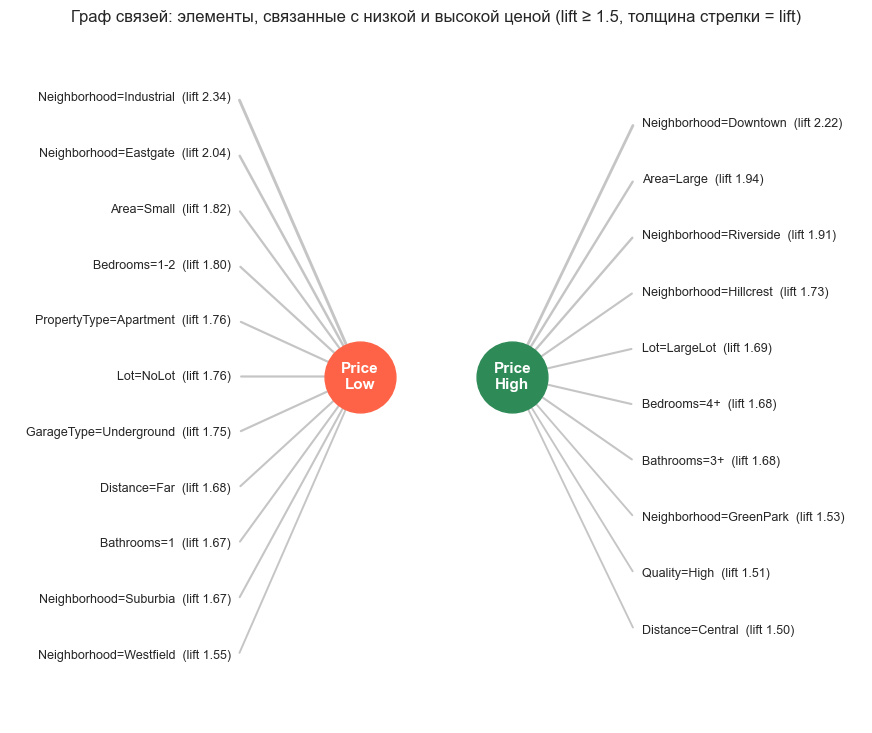

In [26]:
# 4. Граф связей элементов с ценой: слева — элементы, связанные с низкой ценой, справа — с высокой (стрелка «элемент → цена»)
rows = []
for p in ("Price=Low", "Price=High"):
    for o in B.columns:
        if o.startswith("Price=") or B[o].mean() < 0.05:
            continue
        lf = (B[p] & B[o]).mean() / (B[p].mean() * B[o].mean())
        if lf >= 1.5:
            rows.append((o, p, lf))
edges = pd.DataFrame(rows, columns=["item", "price", "lift"])

fig, ax = plt.subplots(figsize=(11, 9))
pos = {"Price=Low": (-1.0, 0.0), "Price=High": (1.0, 0.0)}
for p, x in (("Price=Low", -2.6), ("Price=High", 2.6)):
    sub = edges[edges["price"] == p].sort_values("lift", ascending=False)
    ys = np.linspace(len(sub) / 2, -len(sub) / 2, len(sub)) * 0.45
    for (_, r), y in zip(sub.iterrows(), ys):
        pos[r["item"]] = (x, y)
        ax.annotate("", xy=pos[p], xytext=(x, y),
                    arrowprops=dict(arrowstyle="->", lw=r["lift"] * 0.9, alpha=0.45, color="gray"))
        ax.text(x + (-0.1 if x < 0 else 0.1), y, f"{r['item']}  (lift {r['lift']:.2f})",
                ha="right" if x < 0 else "left", va="center", fontsize=9)
for p, c in (("Price=Low", "tomato"), ("Price=High", "seagreen")):
    ax.scatter(*pos[p], s=2600, color=c, zorder=3)
    ax.text(*pos[p], p.replace("=", "\n"), ha="center", va="center", color="white", fontsize=11, weight="bold", zorder=4)
half = max(edges.groupby("price").size().max(), 1) * 0.45 / 2 + 0.6
ax.set_xlim(-5.6, 5.6)
ax.set_ylim(-half, half)
ax.set_title("Граф связей: элементы, связанные с низкой и высокой ценой (lift ≥ 1.5, толщина стрелки = lift)")
ax.axis("off")
plt.show()

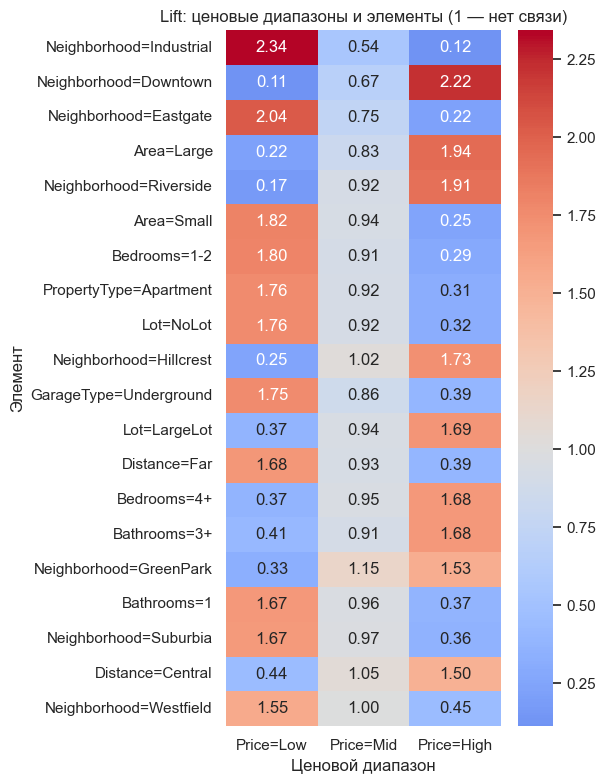

In [27]:
# 5. Тепловая карта lift между ценовыми диапазонами и остальными элементами (парные ассоциации)
price_items = ["Price=Low", "Price=Mid", "Price=High"]
others = [i for i in B.columns if not i.startswith("Price=") and B[i].mean() >= 0.05]
lift_tab = pd.DataFrame({p: [ (B[p] & B[o]).mean() / (B[p].mean() * B[o].mean()) for o in others] for p in price_items}, index=others)
lift_tab = lift_tab.loc[(lift_tab - 1).abs().max(axis=1).sort_values(ascending=False).index].head(20)
plt.figure(figsize=(6, 8))
sns.heatmap(lift_tab, annot=True, fmt=".2f", cmap="coolwarm", center=1)
plt.title("Lift: ценовые диапазоны и элементы (1 — нет связи)")
plt.xlabel("Ценовой диапазон")
plt.ylabel("Элемент")
plt.tight_layout()
plt.show()

In [28]:
# Элементы без связи с ценой (lift около 1): пример «неинформативных» признаков
no_link = (lift_tab_all := pd.DataFrame({p: [(B[p] & B[o]).mean() / (B[p].mean() * B[o].mean()) for o in B.columns if not o.startswith("Price=")]
                                          for p in price_items}, index=[o for o in B.columns if not o.startswith("Price=")]))
spread = (no_link.max(axis=1) - no_link.min(axis=1)).sort_values().head(8)
print("Элементы, слабее всего связанные с ценой (малый размах lift по трём диапазонам):")
print(spread.round(3).to_string())
print("\nПример: RenovationQuality =", {k: round(v, 2) for k, v in no_link.loc[[i for i in no_link.index if i.startswith('RenovationQuality=')]].max(axis=1).items()},
      "(максимальный lift с ценой)")

Элементы, слабее всего связанные с ценой (малый размах lift по трём диапазонам):
Neighborhood=Other      0.001
HeatingType=Other       0.001
HeatingType=District    0.037
HeatingType=Gas         0.044
GarageType=Carport      0.118
Crime=Medium            0.119
School=Medium           0.120
Energy=Medium           0.122

Пример: RenovationQuality = {'RenovationQuality=High': 1.17, 'RenovationQuality=Low': 1.06, 'RenovationQuality=Medium': 1.08} (максимальный lift с ценой)


## Интерпретация результатов


**1. Какие повторяющиеся сочетания найдены (наблюдения).**
- Частые наборы показывают два «типичных профиля»: *маленькие квартиры без участка* (`Lot=NoLot + PropertyType=Apartment` — 30% объектов, `Area=Small + PropertyType=Apartment` — 27%) и *крупные дома* (`Bathrooms=3+ + Bedrooms=4+` — 30%, `Area=Large + Bedrooms=4+` — 30%, `Lot=LargeLot + PropertyType=House` — 25%).
- При `min_support = 0.05` найдено 3808 частых наборов, правил без фильтров — 21 626, после фильтрации — 322. Без жёсткой фильтрации правила невозможно прочитать.

**2. Наиболее содержательные правила (наблюдения).**
- `Area=Large, Distance=Central → Price=High`: support 0.098, confidence 0.865, lift 2.60. Расстояние до центра заметно усиливает правило: добавление `Distance=Central` к условию `Area=Large` повышает достоверность на 0.22 (improvement). Одна большая площадь даёт lift лишь 1.95.
- `Area=Small, Distance=Far → Price=Low`: support 0.101, confidence 0.910, lift 2.73.
- `Neighborhood=Industrial → Price=Low`: support 0.057, confidence 0.78, lift 2.34; `Neighborhood=Downtown` связан с высокой ценой (lift 2.22 на тепловой карте). То есть район сам по себе информативен.
- *Потолок lift.* Каждый ценовой диапазон — это треть объектов (support 0.33), поэтому максимально возможный lift равен 1 / 0.33 ≈ 3.0. Значения 2.6–2.7 — это почти предел, а не «умеренная» связь.

**3. Очевидные и малоинформативные правила (наблюдения).**
- 46% отфильтрованных правил — «ожидаемые» (следствие из той же темы, что и условие). Самый яркий пример: `Lot=NoLot → PropertyType=Apartment` с confidence 0.999 и `GarageType=Underground → PropertyType=Apartment` (0.995). Это почти определения: у квартир нет собственного участка. В данном синтетическом наборе так задано генератором, в реальных данных это тоже тривиально.
- Многие правила «между темами» на деле описывают один скрытый фактор «маленькая квартира» против «большой дом»: `Price=Low, PropertyType=Apartment → Area=Small` — не новая закономерность, а то же самое, записанное по-другому. Формально «между темами» ≠ «неожиданно».
- Элементы без связи с ценой: тип отопления (размах lift по ценовым диапазонам около 0.04), `RenovationQuality` (максимальный lift с ценой 1.17). Правила с ними после фильтров не выживают.

**4. Зависимость от категорий и порога (наблюдения).**
- Lift правила «большая площадь → высокая цена» меняется от 1.46 до 3.00 в зависимости от разбиения; вариант с равными интервалами даёт 3.00–5.00, но «большая площадь» там — всего 0.4% объектов (выбросы). Это пример неудачной категоризации с красивым, но ненадёжным числом.
- Число правил после фильтров падает с 501 при `min_support = 0.03` до 322 при 0.05 и 90 при 0.15; ключевое правило `Area=Large → Price=High` найдено при всех порогах.
- На данных с независимо перемешанными столбцами те же фильтры дают 0 правил (5 повторов), на реальных — 322: правила не объясняются только частотами элементов. При этом фильтр на случайность — эвристика; в первой версии без z-проверки проходили шумовые правила вроде добавления `HeatingType=Gas` в условие.

**5. Apriori и FP-Growth (наблюдение).** Дали идентичные частые наборы и поддержки. В `mlxtend` на этих данных Apriori оказался быстрее (≈0.23 сек против ≈1.16 сек при `min_support = 0.05`). Это особенность реализации и малого размера данных; теоретические преимущества FP-Growth проявляются на больших транзакционных данных.

**6. Почему ассоциация — не причинность (гипотезы).**
- Правило «большая площадь и центральное расположение → высокая цена» не означает, что именно площадь или центр *вызывают* высокую цену: они связаны с типом объекта, участком, качеством и районом (возможные общие причины — *конфаундеры*). Данные синтетические, цена вычислена по формуле, поэтому «закономерности» отражают устройство генератора, а не реальный рынок.
- Ценовые правила — исследовательские ассоциации, а не модель прогноза цены.

**7. Что можно улучшить.** Использовать реальные данные (по возможности с датами сделок), более информативные интервалы, дополнительные меры (leverage, conviction), поправки на множественные сравнения, а для прогноза цены — настоящие модели регрессии или подгруппы (subgroup discovery).


## Заключение
Автоматическая часть формируется по реальным результатам выше.

In [29]:
top_price = price_rules.iloc[0]
exp_share = rules["expected"].mean() * 100
print(f"Транзакций: {len(B)}, элементов: {B.shape[1]}, среднее число элементов в транзакции: {B.sum(axis=1).mean():.1f}.")
print(f"При min_support = {MIN_SUPPORT} найдено {len(fi_ap)} частых наборов (Apriori и FP-Growth дали одинаковый результат: {set_ap == set_fp}).")
print(f"Правил без фильтров: {len(rules_all)}; после фильтрации (conf ≥ 0.6, lift ≥ 1.2, improvement ≥ 0.02, z ≥ 2): {len(rules)}; "
      f"из них ожидаемых (внутри одной темы): {exp_share:.0f}%.")
print(f"На данных с перемешанными столбцами те же фильтры пропускают {counts} правил, на реальных — {len(rules)}.")
print(f"Самое сильное правило со следствием «цена»: {top_price['rule']} "
      f"(support = {top_price['support']:.3f}, confidence = {top_price['confidence']:.2f}, lift = {top_price['lift']:.2f}).")

Транзакций: 2800, элементов: 75, среднее число элементов в транзакции: 16.9.
При min_support = 0.05 найдено 3804 частых наборов (Apriori и FP-Growth дали одинаковый результат: True).
Правил без фильтров: 21602; после фильтрации (conf ≥ 0.6, lift ≥ 1.2, improvement ≥ 0.02, z ≥ 2): 324; из них ожидаемых (внутри одной темы): 46%.
На данных с перемешанными столбцами те же фильтры пропускают [0, 0, 0, 0, 0] правил, на реальных — 324.
Самое сильное правило со следствием «цена»: Area=Large, Bathrooms=3+, Distance=Central  →  Price=High (support = 0.077, confidence = 0.91, lift = 2.74).
